# Workshop 2 - Object detection using web camera
## Name : DEVI S
## Register number : 212225100008

In [4]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
model = YOLO("yolov8m.pt")

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


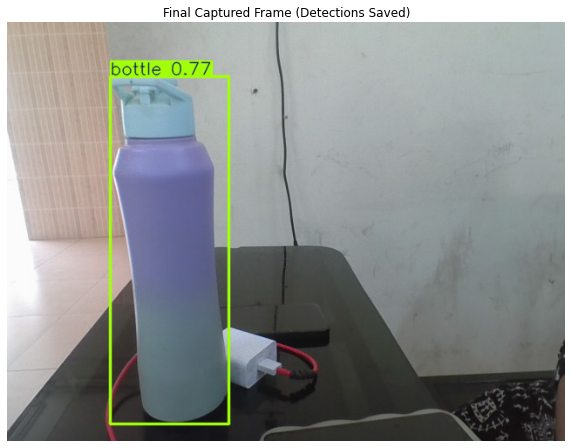

Stream ended. Final detection frozen above.


In [3]:
import cv2
from IPython.display import clear_output
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load model
model = YOLO("yolov8m.pt")

# Open webcam
cap = cv2.VideoCapture(0)

# Variable to hold the last valid detected frame
last_frame = None

if not cap.isOpened():
    print("Error: Could not open webcam.")
else:
    print("Streaming started. Stop/Interrupt the cell when you want to freeze the final frame.")
    try:
        while True:
            ret, frame = cap.read()
            if not ret:
                print("Failed to capture frame.")
                break

            # Object detection
            results = model(frame, conf=0.60, verbose=False)

            # Annotate and convert BGR to RGB
            annotated_frame = results[0].plot()
            annotated_frame = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

            # Store the current frame as the last active frame
            last_frame = annotated_frame

            # Live update inside Jupyter
            clear_output(wait=True)
            plt.figure(figsize=(10, 8))
            plt.imshow(annotated_frame)
            plt.title("Real-Time Object Detection (Interrupt to Stop)")
            plt.axis("off")
            plt.show()

    except KeyboardInterrupt:
        print("\nStream stopped by user.")
    finally:
        # Release the webcam hardware
        cap.release()
        cv2.destroyAllWindows()
        plt.close("all")

        # Permanently display the final detected frame
        if last_frame is not None:
            clear_output(wait=True)
            plt.figure(figsize=(10, 8))
            plt.imshow(last_frame)
            plt.title("Final Captured Frame (Detections Saved)")
            plt.axis("off")
            plt.show()

            # Optional: save to an image file on disk
            # cv2.imwrite("final_detection.jpg", cv2.cvtColor(last_frame, cv2.COLOR_RGB2BGR))
            print("Stream ended. Final detection frozen above.")
        else:
            print("No frames were captured.")